<a href="https://colab.research.google.com/github/dptel22/Nosh-Robotics/blob/main/Task_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Pull SAM 3 model

In [1]:
!git clone https://github.com/facebookresearch/sam3.git
!pip install -q -e ./sam3


Cloning into 'sam3'...
remote: Enumerating objects: 1502, done.
remote: Counting objects: 100% (54/54), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 1502 (delta 29), reused 11 (delta 11), pack-reused 1448 (from 3)
Receiving objects: 100% (1502/1502), 60.70 MiB | 26.52 MiB/s, done.
Resolving deltas: 100% (580/580), done.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for sam3 (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the 

#Hugging face login

In [1]:
from google.colab import userdata
from huggingface_hub import login
login(userdata.get("HF_TOKEN"))

#Load the data

In [2]:
#!unzip -q "/content/egg.v3i.folder.zip" -d /content/

In [3]:
from pathlib import Path

# Define the simple path to your extracted dataset
dataset_dir = Path("/content/egg.v3i.folder")

# Find all images in the dataset folder
valid_extensions = {".jpg", ".jpeg", ".png", ".webp"}
all_images = [p for p in dataset_dir.rglob("*") if p.is_file() and p.suffix.lower() in valid_extensions]

# Print loading summary
print(f"Dataset Folder: {dataset_dir.absolute()}")
print(f"Total Images Loaded: {len(all_images)}")
if all_images:
    print("Example Image Path:", all_images[0])
else:
    print("No images found. Please verify the unzip command executed fully.")

Dataset Folder: /content/egg.v3i.folder
Total Images Loaded: 160
Example Image Path: /content/egg.v3i.folder/train/egg/not_damaged_128_jpg.rf.6858d59b27b6c88c6e18cb85dbe6fff7.jpg


#Check the environment

In [4]:
import sys
import numpy as np
import torch

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("NumPy test:", np.random.rand(3))

from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor

print("SAM 3 imports successful")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 1.26.4
PyTorch: 2.11.0+cu130
CUDA available: True
NumPy test: [0.48641627 0.38628378 0.47254024]


/content/sam3/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/content/sam3/sam3/model/model_misc.py:71: UserWarning: Flash Attention is disabled as it requires a GPU with Ampere (8.0) CUDA capability.
  OLD_GPU, USE_FLASH_ATTN, MATH_KERNEL_ON = get_sdpa_settings()


SAM 3 imports successful


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


#Load SAM 3

In [5]:
import os
device = "cuda" if torch.cuda.is_available() else "cpu"

# Manually define the BPE vocabulary path to bypass the pkg_resources error
bpe_path = "/content/sam3/sam3/assets/bpe_simple_vocab_16e6.txt.gz"
if not os.path.exists(bpe_path):
    # fallback to local relative path if needed
    bpe_path = "sam3/sam3/assets/bpe_simple_vocab_16e6.txt.gz"

model = build_sam3_image_model(bpe_path=bpe_path, device=device)
model.eval()

processor = Sam3Processor(
    model,
    device=device,
    confidence_threshold=0.30,
)

print("SAM 3 loaded on:", device)

SAM 3 loaded on: cuda


# Define segmentation and mask processing

In [9]:
from PIL import Image
import numpy as np
import torch

def segment_image(path):
    image = Image.open(path).convert("RGB")

    with torch.inference_mode():
        state = processor.set_image(image)
        result = processor.set_text_prompt(
            state=state,
            prompt="egg",
        )

    # Cast to float to safely convert from BFloat16 to NumPy
    masks = result["masks"].detach().float().cpu().numpy()
    if masks.ndim == 4:
        masks = masks[:, 0]  # (N, 1, H, W) -> (N, H, W)

    masks = masks.astype(bool)
    scores = result["scores"].detach().float().cpu().numpy().reshape(-1)

    return image, masks, scores


def select_masks(masks, scores, min_area=0.002, max_area=0.98, iou_threshold=0.70):
    """Keep plausible-sized masks and remove near-identical duplicates."""
    if len(masks) == 0:
        return []

    valid = [
        i for i, mask in enumerate(masks)
        if min_area <= mask.mean() <= max_area
    ]

    kept = []

    for i in sorted(valid, key=lambda j: scores[j], reverse=True):
        duplicate = False

        for j in kept:
            intersection = np.logical_and(masks[i], masks[j]).sum()
            union = np.logical_or(masks[i], masks[j]).sum()

            if union and intersection / union > iou_threshold:
                duplicate = True
                break

        if not duplicate:
            kept.append(i)

    return kept


def make_overlay(image, masks, scores, kept):
    """Colour the egg masks over the original image."""
    result = np.asarray(image).copy()

    colours = [
        (255, 60, 60),
        (40, 220, 100),
        (40, 140, 255),
        (255, 190, 30),
        (210, 70, 255),
    ]

    for instance_id, i in enumerate(kept):
        mask = masks[i]
        colour = np.array(colours[instance_id % len(colours)], dtype=np.uint8)

        result[mask] = (
            0.55 * result[mask] + 0.45 * colour
        ).astype(np.uint8)

        # Mark the mask boundary without requiring OpenCV.
        eroded = np.zeros_like(mask)
        eroded[1:-1, 1:-1] = (
            mask[1:-1, 1:-1]
            & mask[:-2, 1:-1]
            & mask[2:, 1:-1]
            & mask[1:-1, :-2]
            & mask[1:-1, 2:]
        )
        result[mask & ~eroded] = colour

    return Image.fromarray(result)

# Test on one image

Image: not_damaged_128_jpg.rf.6858d59b27b6c88c6e18cb85dbe6fff7.jpg
Raw detections: 2
Masks after duplicate removal: 2
Confidence scores: [0.969, 0.957]


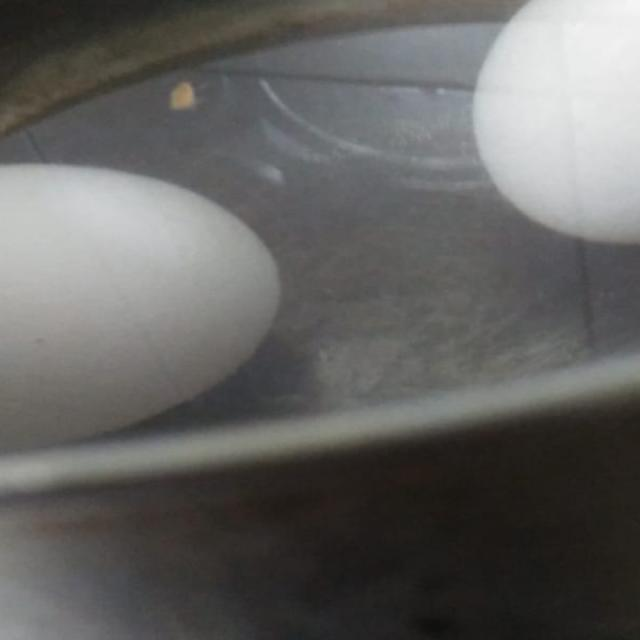

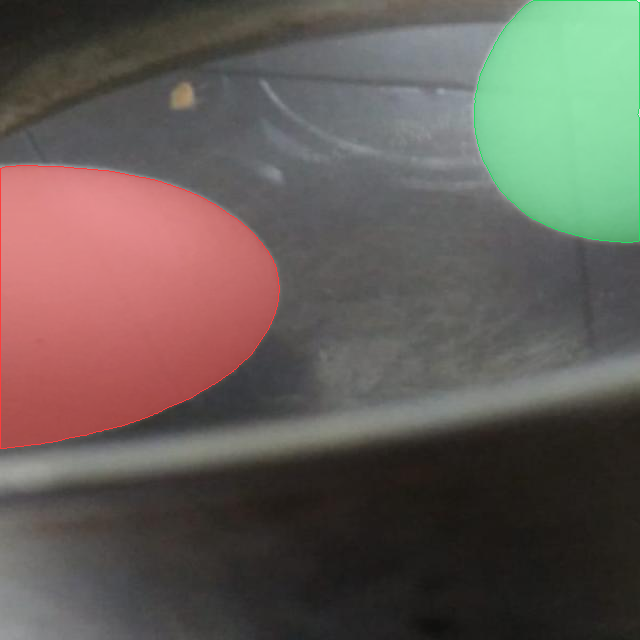

In [10]:
from IPython.display import display
import torch

# Map the loaded dataset images variable
image_paths = all_images
sample_path = image_paths[0]

# Wrap the segmentation call with automatic mixed precision autocasting to prevent the dtype mismatch
with torch.autocast(device_type=device, dtype=torch.bfloat16):
    image, masks, scores = segment_image(sample_path)

kept = select_masks(masks, scores)

print("Image:", sample_path.name)
print("Raw detections:", len(masks))
print("Masks after duplicate removal:", len(kept))
print("Confidence scores:", [round(float(scores[i]), 3) for i in kept])

display(image)
display(make_overlay(image, masks, scores, kept))

# Process every image and save the results

In [13]:
import csv
import time
import torch
from pathlib import Path
from PIL import Image
import numpy as np

# Map the dataset directory to DATA_DIR
DATA_DIR = dataset_dir

OUT_DIR = Path("/content/task1_outputs")

MASK_DIR = OUT_DIR / "sam_masks"
UNION_DIR = OUT_DIR / "union_masks"
OVERLAY_DIR = OUT_DIR / "sam_overlays"
REPORT_PATH = OUT_DIR / "sam_report.csv"

for folder in (MASK_DIR, UNION_DIR, OVERLAY_DIR):
    folder.mkdir(parents=True, exist_ok=True)

fields = [
    "image", "split", "n_raw", "n_eggs",
    "scores", "areas", "flags", "seconds",
]

def get_split(path):
    # Helper to extract train/test/valid from the directory structure
    for part in path.parts:
        if part in {"train", "test", "valid"}:
            return part
    return "unknown"

completed = set()

if REPORT_PATH.exists() and REPORT_PATH.stat().st_size > 0:
    with REPORT_PATH.open(newline="") as f:
        completed = {row["image"] for row in csv.DictReader(f)}

report_exists = REPORT_PATH.exists() and REPORT_PATH.stat().st_size > 0

with REPORT_PATH.open("a", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fields)

    if not report_exists:
        writer.writeheader()

    for position, path in enumerate(image_paths, start=1):
        relative_path = path.relative_to(DATA_DIR)
        key = relative_path.as_posix()

        mask_path = (MASK_DIR / relative_path).with_suffix(".png")
        union_path = (UNION_DIR / relative_path).with_suffix(".png")
        overlay_path = (OVERLAY_DIR / relative_path).with_suffix(".jpg")

        # Resume safely if all outputs for this image already exist.
        if (
            key in completed
            and mask_path.exists()
            and union_path.exists()
            and overlay_path.exists()
        ):
            continue

        start = time.time()

        # Use autocast context to maintain data-type safety
        with torch.autocast(device_type=device, dtype=torch.bfloat16):
            image, masks, scores = segment_image(path)

        kept = select_masks(masks, scores)

        height, width = np.asarray(image).shape[:2]

        # 0 = background; 1, 2, ... = individual egg instances.
        labels = np.zeros((height, width), dtype=np.uint16)

        for label_id, i in enumerate(kept, start=1):
            mask = masks[i]
            labels[mask & (labels == 0)] = label_id

        # Binary union mask for later pixel-level evaluation.
        union = (labels > 0).astype(np.uint8) * 255

        for output_path in (mask_path, union_path, overlay_path):
            output_path.parent.mkdir(parents=True, exist_ok=True)

        Image.fromarray(labels).save(mask_path)
        Image.fromarray(union).save(union_path)
        make_overlay(image, masks, scores, kept).save(overlay_path, quality=90)

        areas = [float(masks[i].mean()) for i in kept]
        selected_scores = [float(scores[i]) for i in kept]

        flags = []
        if not kept:
            flags.append("NO_DETECTION")
        if len(kept) > 1:
            flags.append("MULTI_EGG")
        if any(s < 0.5 for s in selected_scores):
            flags.append("LOW_SCORE")
        if any(a > 0.90 for a in areas):
            flags.append("VERY_LARGE_MASK")

        writer.writerow({
            "image": key,
            "split": get_split(path),
            "n_raw": len(masks),
            "n_eggs": len(kept),
            "scores": ";".join(f"{s:.3f}" for s in selected_scores),
            "areas": ";".join(f"{a:.4f}" for a in areas),
            "flags": "|".join(flags),
            "seconds": f"{time.time() - start:.2f}",
        })
        f.flush()

        print(
            f"[{position}/{len(image_paths)}] {path.name}: "
            f"{len(kept)} egg(s) | {','.join(flags) or 'OK'}"
        )

print("\nTask 1 inference finished.")
print("Saved outputs:", OUT_DIR)

[1/160] not_damaged_128_jpg.rf.6858d59b27b6c88c6e18cb85dbe6fff7.jpg: 2 egg(s) | MULTI_EGG
[2/160] not_damaged_141_jpg.rf.83e45bf8f68d19a25dab3adff0d149bb.jpg: 1 egg(s) | OK
[3/160] not_damaged_95_jpg.rf.f9c657b9c805933351457e145384c5ec.jpg: 1 egg(s) | OK
[4/160] not_damaged_39_jpg.rf.ef9d98f04184a2067548ff9684ad0c71.jpg: 1 egg(s) | OK
[5/160] not_damaged_17_jpg.rf.b2fb006fc935da7f59004c6d437df7b7.jpg: 1 egg(s) | OK
[6/160] not_damaged_28_jpg.rf.407c3fb66444dde44053d05fb9bae474.jpg: 1 egg(s) | OK
[7/160] not_damaged_148_jpg.rf.19580eb17895af5977417f8259c53eef.jpg: 3 egg(s) | MULTI_EGG
[8/160] not_damaged_108_jpg.rf.a33af29f3c7418568afac5dbc975a0da.jpg: 1 egg(s) | OK
[9/160] not_damaged_33_jpg.rf.3c8dbd042e606fca400f87b4e6c47b34.jpg: 1 egg(s) | OK
[10/160] not_damaged_113_jpg.rf.f140584ff8941a85f0b65ee84ea26fdd.jpg: 2 egg(s) | MULTI_EGG
[11/160] not_damaged_92_jpg.rf.a0eeeebb632bbe97c5ab3df4c815a151.jpg: 1 egg(s) | OK
[12/160] not_damaged_156_jpg.rf.748940700561c705b27aae03b3c230b1.jpg: 

# Review the overlays and failures

In [14]:
with REPORT_PATH.open(newline="") as f:
    rows = list(csv.DictReader(f))

print("Images processed:", len(rows))
print("No-detection images:", sum("NO_DETECTION" in r["flags"] for r in rows))
print("Flagged images:", sum(bool(r["flags"]) for r in rows))

for row in rows:
    if row["flags"]:
        print(row["image"], "->", row["flags"])

Images processed: 160
No-detection images: 10
Flagged images: 34
train/egg/not_damaged_128_jpg.rf.6858d59b27b6c88c6e18cb85dbe6fff7.jpg -> MULTI_EGG
train/egg/not_damaged_148_jpg.rf.19580eb17895af5977417f8259c53eef.jpg -> MULTI_EGG
train/egg/not_damaged_113_jpg.rf.f140584ff8941a85f0b65ee84ea26fdd.jpg -> MULTI_EGG
train/egg/not_damaged_123_jpg.rf.66fc8ae2f37e2b9bf90327a08f611f8d.jpg -> LOW_SCORE
train/egg/not_damaged_22_jpg.rf.c9deb637c04ba0ec28a7256430230227.jpg -> MULTI_EGG|LOW_SCORE
train/egg/not_damaged_117_jpg.rf.f9be247b38715de393303f98da60c14c.jpg -> NO_DETECTION
train/egg/not_damaged_114_jpg.rf.612183354ee6b6996341f0ddf612f74c.jpg -> MULTI_EGG
train/egg/not_damaged_44_jpg.rf.6792484ee57640260db98775b84ab485.jpg -> NO_DETECTION
train/egg/not_damaged_151_jpg.rf.e1607a3d17d5b9755e6cd20f8fc550a4.jpg -> MULTI_EGG
train/egg/not_damaged_105_jpg.rf.74758bab991f2338b5072e5af7ba6862.jpg -> MULTI_EGG
train/egg/not_damaged_142_jpg.rf.85ad5fb95e23f0f8c5a7b45be2b70340.jpg -> MULTI_EGG
train/eg

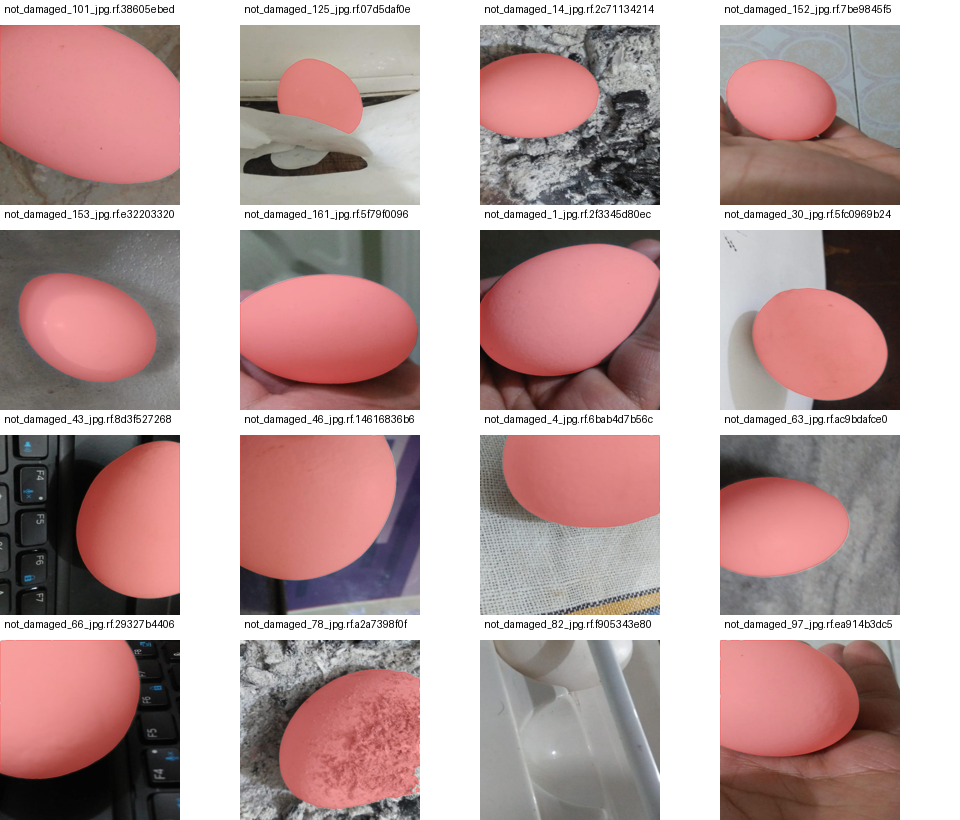

In [15]:
from PIL import ImageDraw
from IPython.display import display
import math

overlay_files = sorted(OVERLAY_DIR.rglob("*.jpg"))[:16]

cols = 4
thumb_w, thumb_h = 240, 180
cell_h = thumb_h + 25
sheet = Image.new(
    "RGB",
    (cols * thumb_w, math.ceil(len(overlay_files) / cols) * cell_h),
    "white",
)
draw = ImageDraw.Draw(sheet)

for i, path in enumerate(overlay_files):
    thumb = Image.open(path).convert("RGB")
    thumb.thumbnail((thumb_w, thumb_h))

    x = (i % cols) * thumb_w
    y = (i // cols) * cell_h

    draw.text((x + 4, y + 3), path.name[:32], fill="black")
    sheet.paste(thumb, (x, y + 25))

display(sheet)

# Download Output

In [16]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/task1_outputs",
    "zip",
    root_dir=OUT_DIR,
)

print("Archive created:", zip_path)
files.download(zip_path)

Archive created: /content/task1_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>